In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [6]:
titanic=sns.load_dataset("titanic")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [7]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [8]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [9]:
feature=["pclass", "sex", "fare", "embarked", "age"]
target=["survived"]

In [10]:
#Filling Null values
from sklearn.impute import SimpleImputer
imp_med=SimpleImputer(strategy="median")
titanic[["age"]]= imp_med.fit_transform(titanic[["age"]])
imp_feq=SimpleImputer(strategy="most_frequent")
titanic[["embarked"]]=imp_feq.fit_transform(titanic[["embarked"]])

In [11]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [12]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [13]:
#Encoding
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
le= LabelEncoder()
titanic["sex"]= le.fit_transform(titanic["sex"])
titanic["embarked"]= le.fit_transform(titanic["embarked"])
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,2,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,0,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,2,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,2,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,2,Third,man,True,NaN,Southampton,no,True


In [14]:
X=titanic[feature]
Y=titanic[target]
Y.head()

,survived
0,0
1,1
2,1
3,1
4,0


In [15]:
x_train, x_test, y_train, y_test=train_test_split(X, Y, test_size=0.2, random_state=42)
x_test.head()

,pclass,sex,fare,embarked,age
709,3,1,15.2458,0,28.0
439,2,1,10.5000,2,31.0
840,3,1,7.9250,2,20.0
720,2,0,33.0000,2,6.0
39,3,0,11.2417,0,14.0


In [16]:
#Decision Tree with no pruning
from sklearn.tree import DecisionTreeClassifier
model=DecisionTreeClassifier()
model.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [17]:
from sklearn.metrics import accuracy_score
y_pred= model.predict(x_test)
print("Accuracy Score:", accuracy_score(y_test, y_pred))

Accuracy Score: 0.7653631284916201


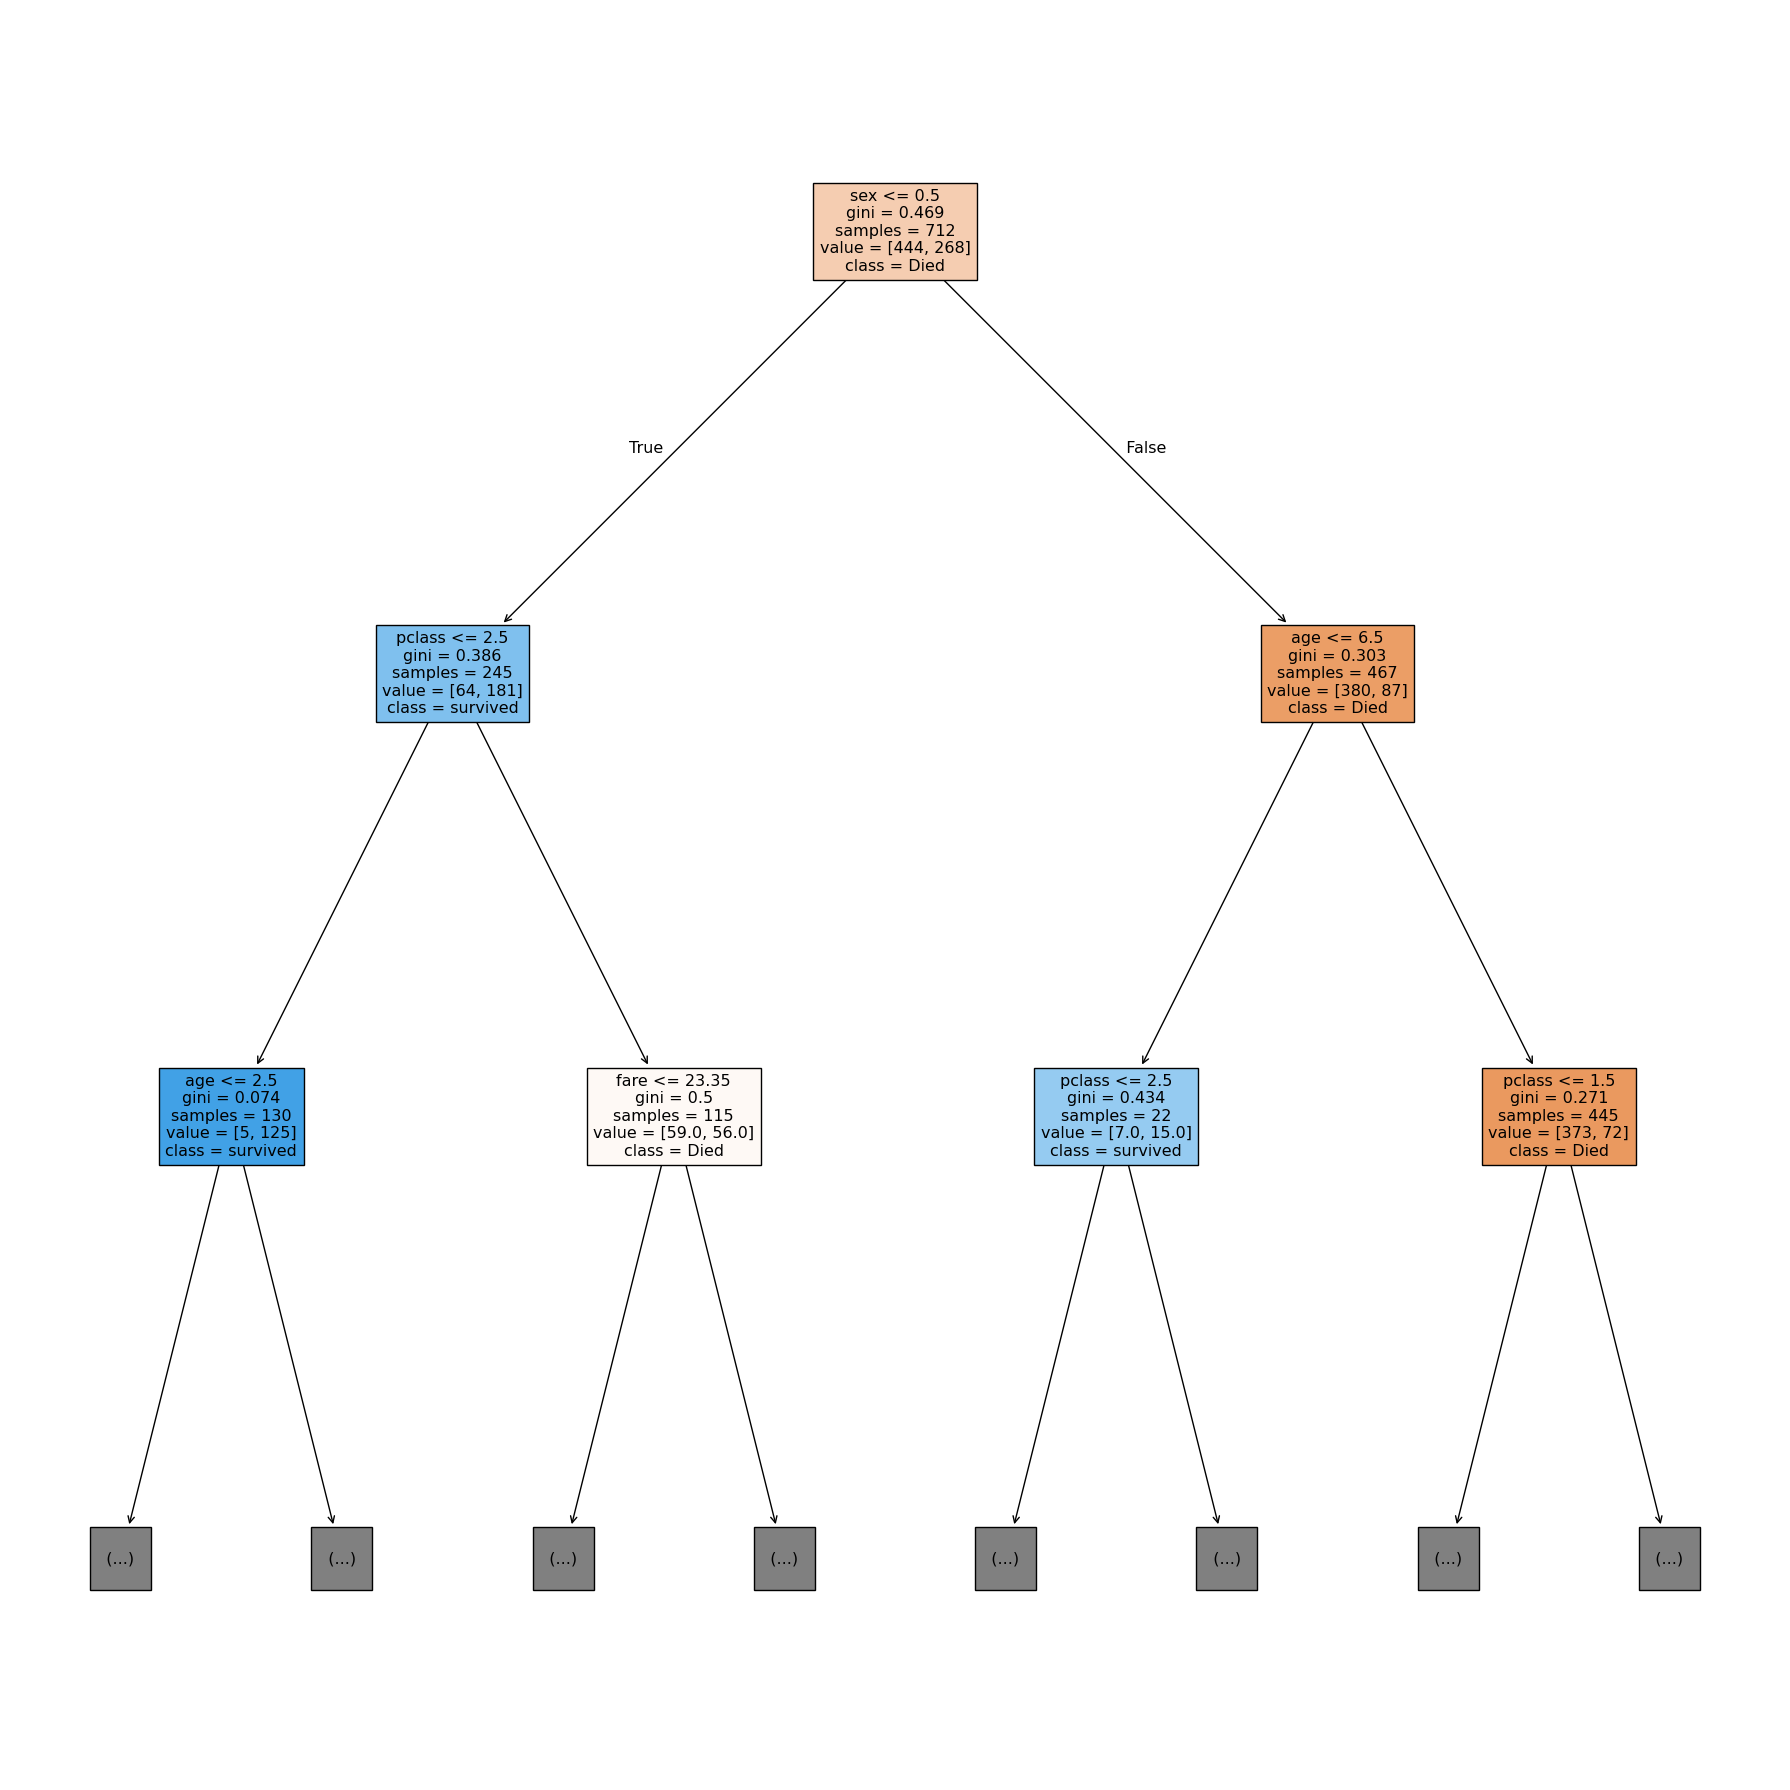

In [18]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18,18))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died", "survived"],
    max_depth=2,
    filled=True
)
plt.tight_layout()
plt.show()

for depth=2, accuracy=0.7653631284916201
for depth=3, accuracy=0.7988826815642458
for depth=4, accuracy=0.7988826815642458
for depth=5, accuracy=0.7988826815642458
for depth=6, accuracy=0.8044692737430168
for depth=9, accuracy=0.7932960893854749
for depth=10, accuracy=0.7877094972067039


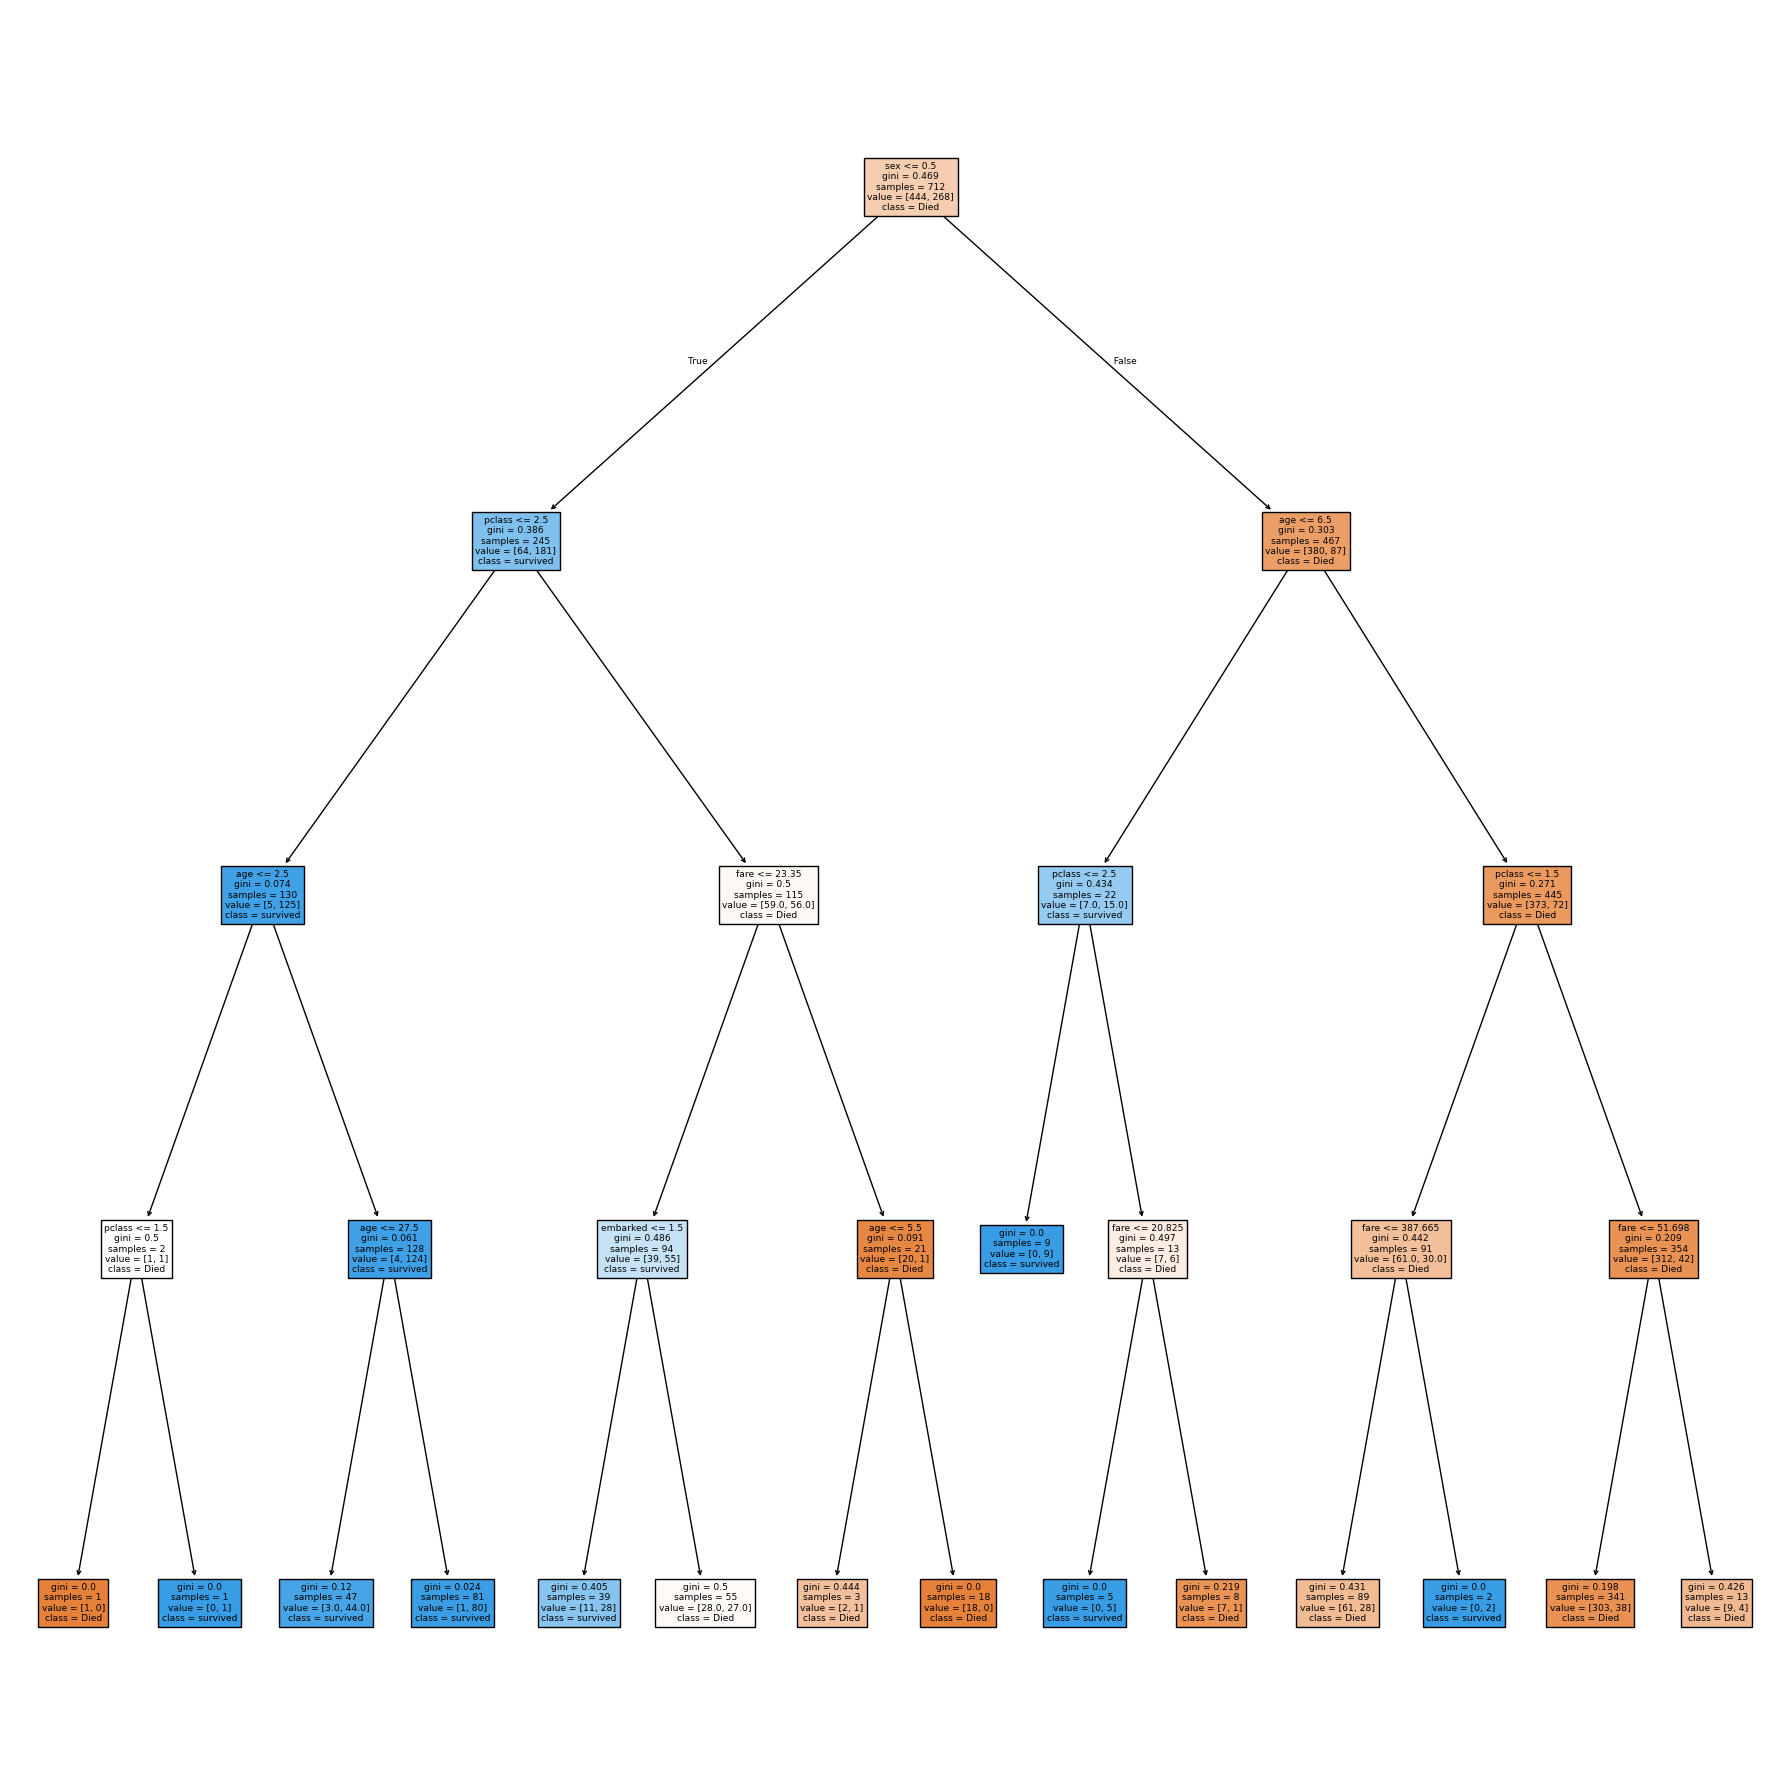

In [35]:
#Dicision Tree with per-pruning
max_depth=[2,3,4,5,6,9,10]
for depth in max_depth:
    model=DecisionTreeClassifier(max_depth=depth)
    model.fit(x_train, y_train)
    acc=model.score(x_test, y_test)
    print(f"for depth={depth}, accuracy={acc}")

    if depth==4:
     plt.figure(figsize=(18,18))
     plot_tree(
     model,
     feature_names=X.columns,
     class_names=["Died", "survived"],
     
     filled=True
   )
plt.tight_layout()
plt.show()   

for sample split=5, accuracy=0.7988826815642458
for sample split=10, accuracy=0.7988826815642458
for sample split=15, accuracy=0.7988826815642458
for sample split=20, accuracy=0.7988826815642458
for sample split=25, accuracy=0.7932960893854749
for sample split=30, accuracy=0.7932960893854749


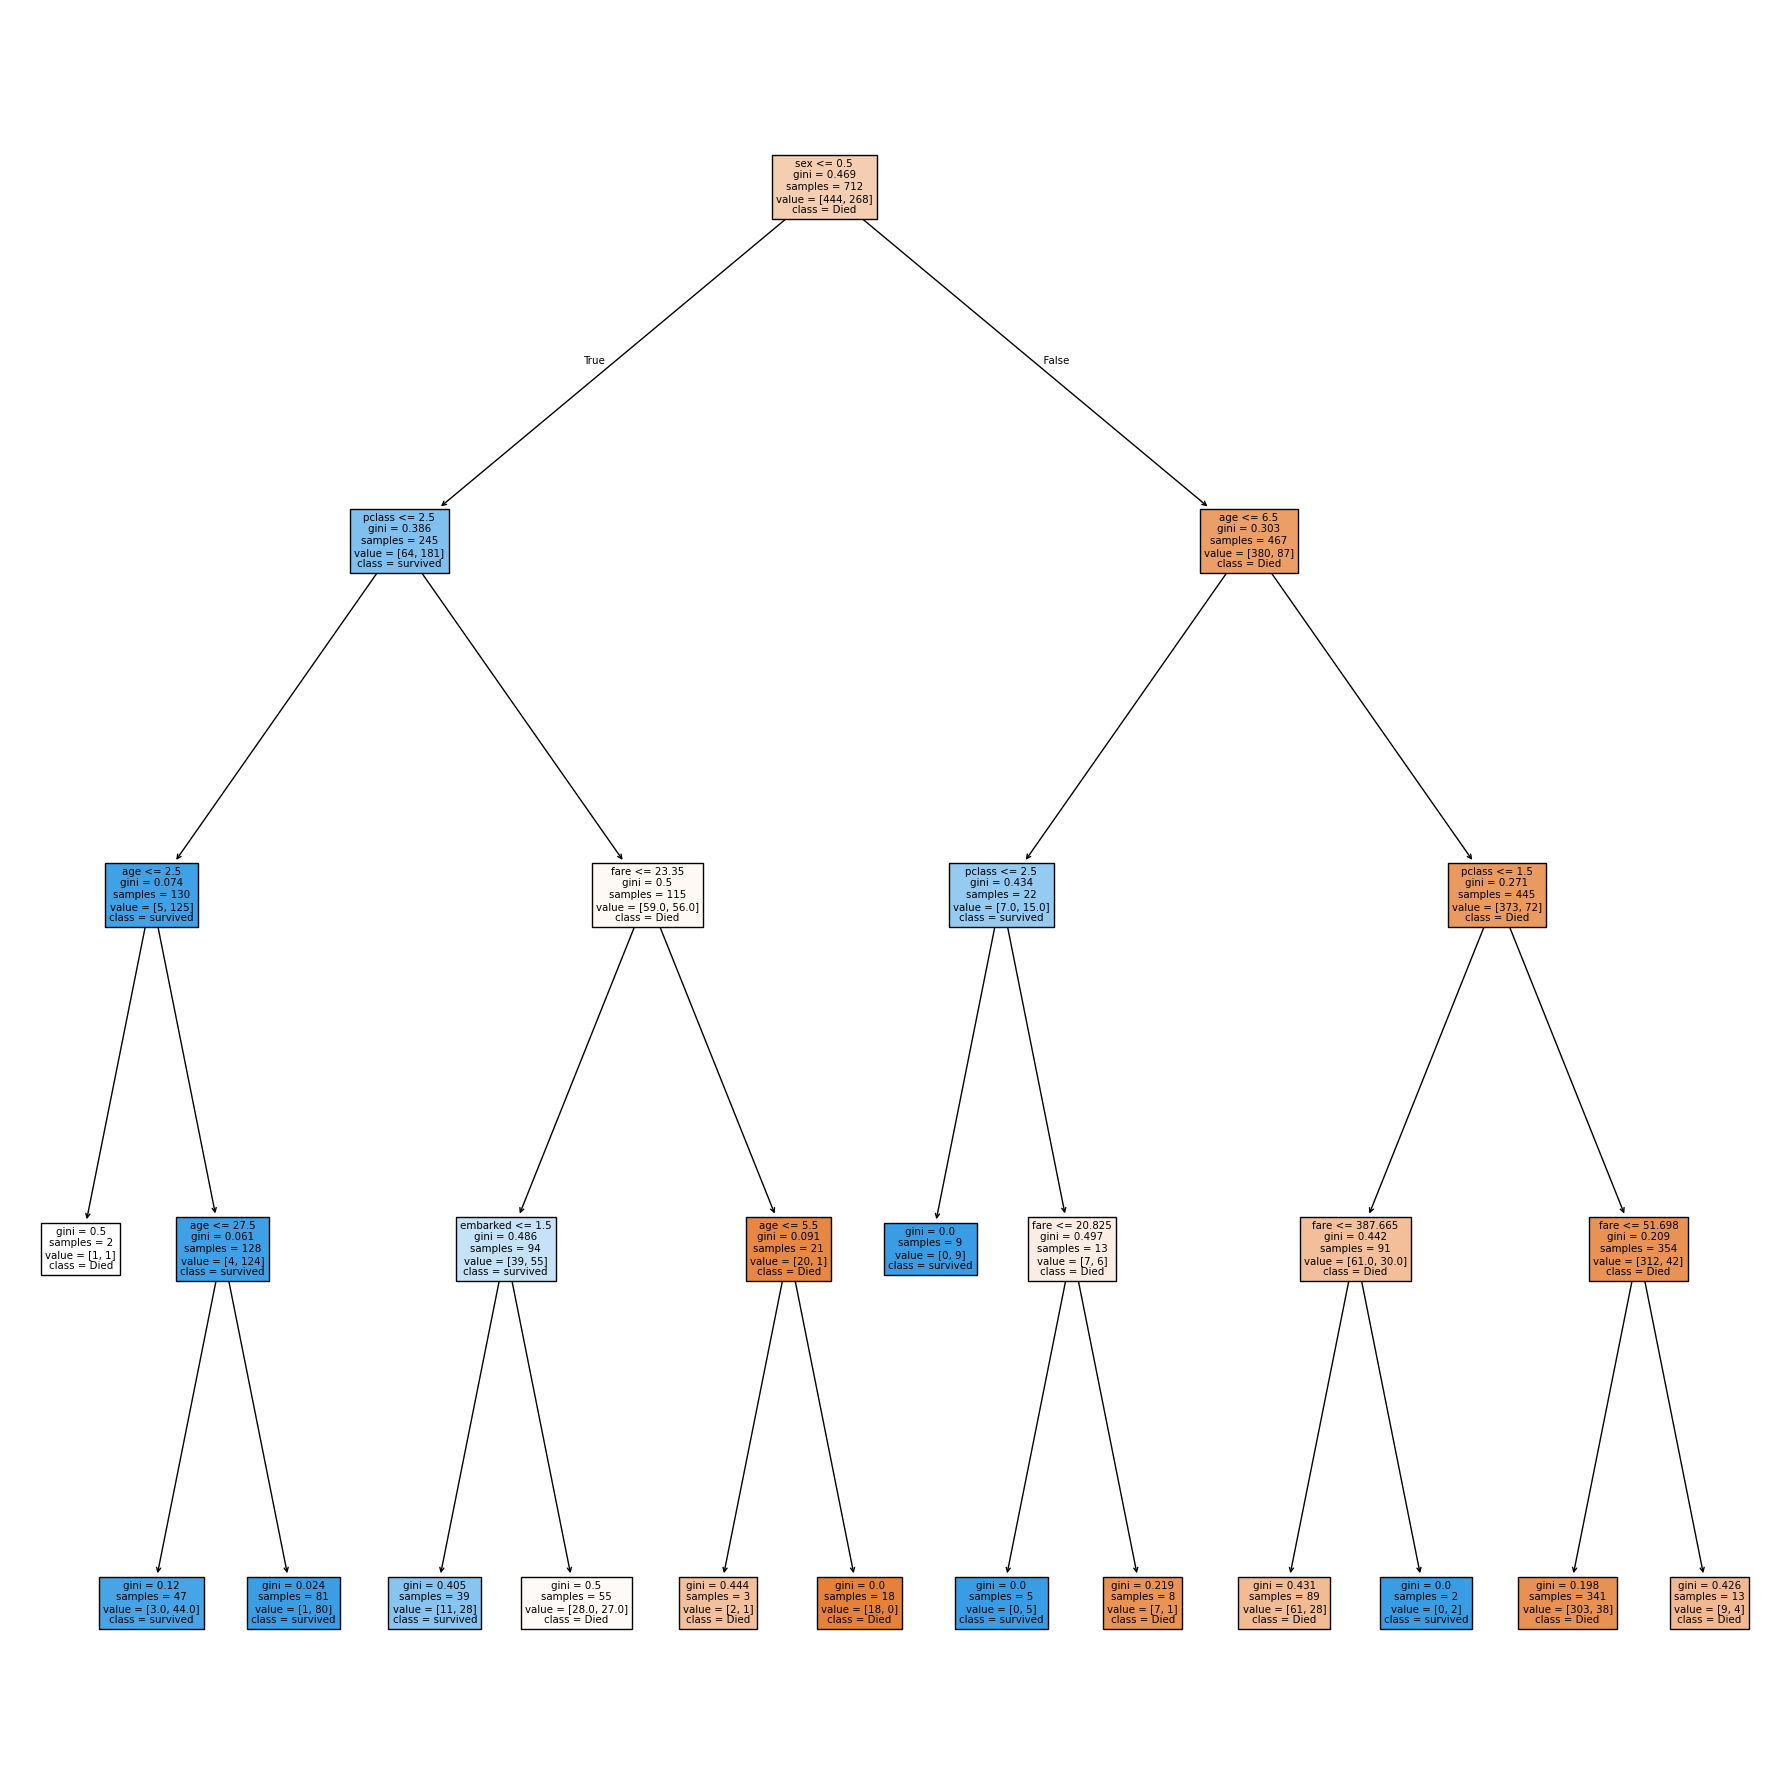

In [36]:
#Dicision Tree with per-pruning
min_samples_split=[5,10,15,20,25,30]
for split in min_samples_split:
    model=DecisionTreeClassifier(max_depth=4, min_samples_split=split)
    model.fit(x_train, y_train)
    acc=model.score(x_test, y_test)
    print(f"for sample split={split}, accuracy={acc}")

    if split==10:
     plt.figure(figsize=(18,18))
     plot_tree(
     model,
     feature_names=X.columns,
     class_names=["Died", "survived"],
     filled=True
   )
plt.tight_layout()
plt.show()   

In [37]:
#Decision Tree with out Pruning
full_tree=DecisionTreeClassifier(random_state=42)
full_tree.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [38]:
path=full_tree.cost_complexity_pruning_path(x_train, y_train)
ccp_alphas=path.ccp_alphas
print(ccp_alphas)

[0.00000000e+00 0.00000000e+00 6.68806849e-05 1.45921494e-04
 1.84428555e-04 2.00642055e-04 2.34082397e-04 2.34082397e-04
 3.51123596e-04 4.68164794e-04 4.68164794e-04 5.61797753e-04
 6.24219725e-04 6.67991230e-04 7.02247191e-04 7.02247191e-04
 8.19288390e-04 8.19288390e-04 8.32292967e-04 8.42696629e-04
 8.42696629e-04 8.42696629e-04 8.94231048e-04 8.99610781e-04
 9.24769963e-04 9.36329588e-04 9.36329588e-04 9.36329588e-04
 9.88347898e-04 1.00253471e-03 1.05337079e-03 1.07400895e-03
 1.08038029e-03 1.11865144e-03 1.12359551e-03 1.12359551e-03
 1.13139825e-03 1.17041199e-03 1.18841832e-03 1.22566125e-03
 1.22893258e-03 1.22893258e-03 1.24361593e-03 1.24843945e-03
 1.27565833e-03 1.30996111e-03 1.33761370e-03 1.37044603e-03
 1.46301498e-03 1.47927070e-03 1.51142557e-03 1.54072312e-03
 1.56675436e-03 1.60434338e-03 1.66892062e-03 1.76144762e-03
 1.86751451e-03 2.10674157e-03 2.34082397e-03 2.41226470e-03
 2.64273538e-03 2.69412911e-03 3.43770913e-03 3.56327570e-03
 5.47433606e-03 9.055400

In [41]:
#training model for all alphas
tree=[]
for alpha in ccp_alphas:
    model=DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    model.fit(x_train, y_train)
    tree.append((model, alpha))

In [45]:
best_acc=0
best_alpha=0
for model, alpha in tree:
    curr_acc=model.score(x_test, y_test)
    if curr_acc>best_acc:
        best_acc=curr_acc
        best_alpha=alpha

In [46]:
best_acc

0.8379888268156425

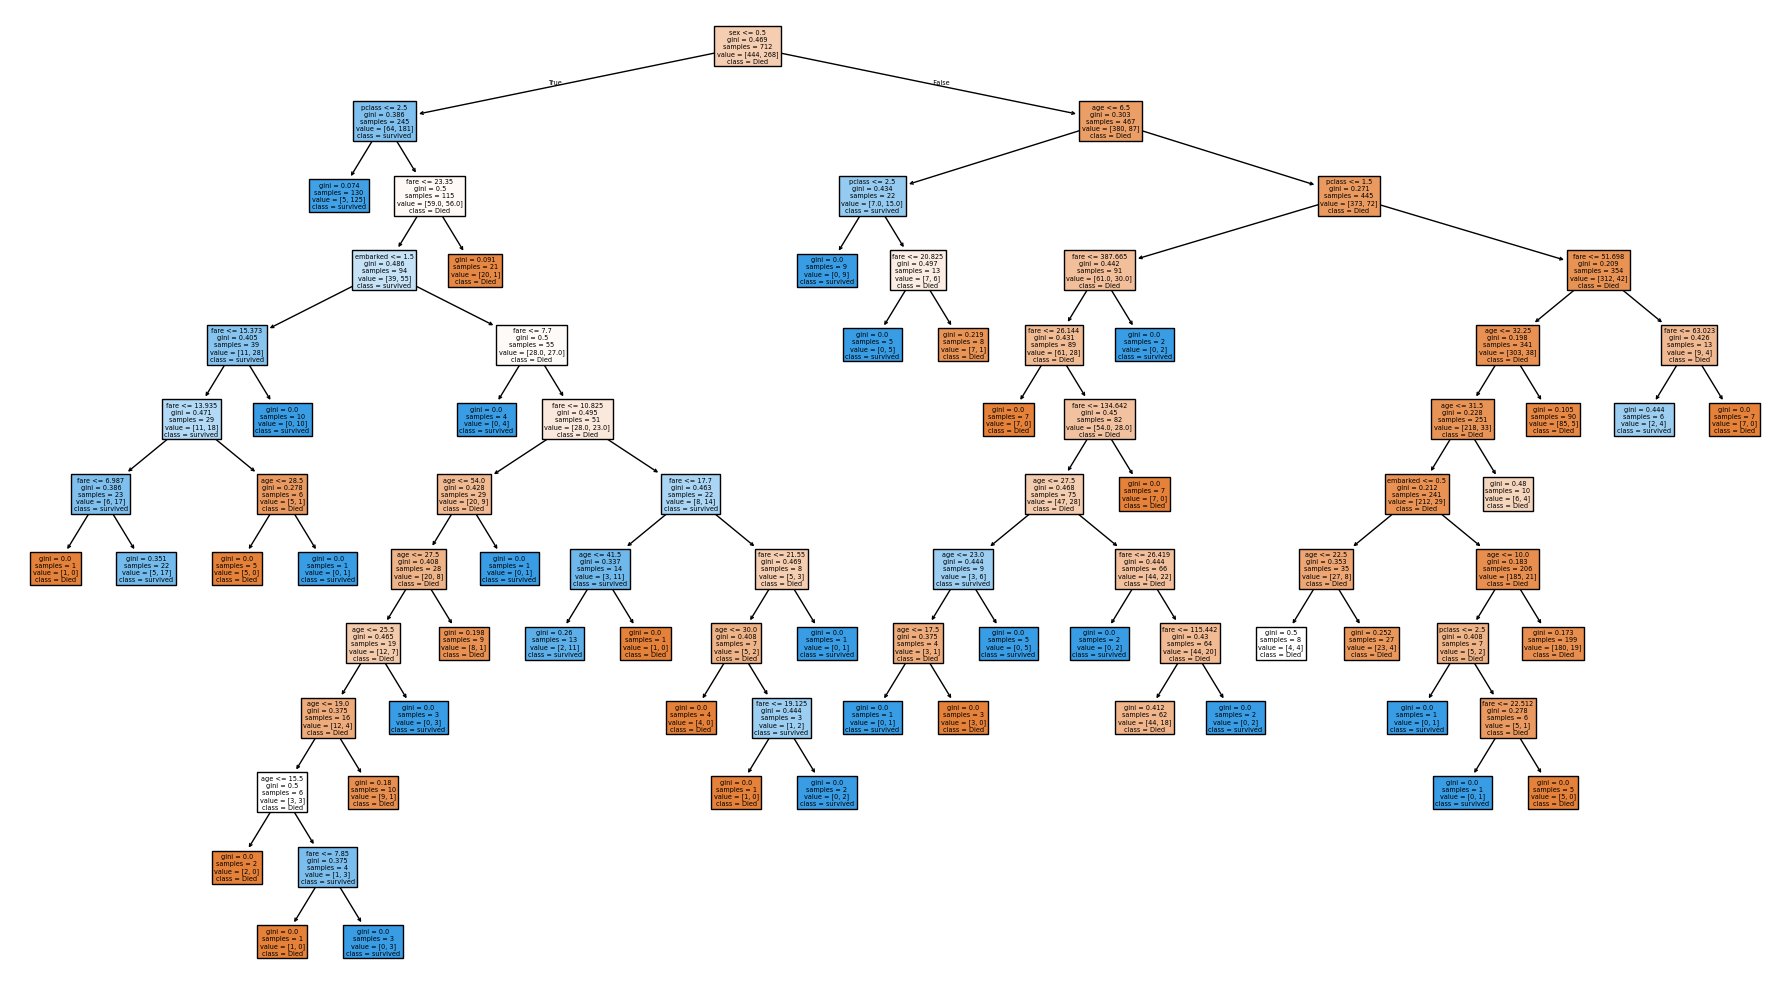

In [48]:
best_model=DecisionTreeClassifier(ccp_alpha=best_alpha)
best_model.fit(x_train, y_train)
plt.figure(figsize=(18,10))
plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=["Died", "survived"],
     filled=True
   )
plt.tight_layout()
plt.show()   

In [51]:
print(best_model.score(x_test, y_test))

0.8379888268156425
